### In this notebook I tried a different approach with combining the datasets and did some EDA with the whole set

In [46]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

In [47]:
# Combining the datasets together with a new column for run_id and road_id

dfA1 = pd.read_csv("../dataset/cleaned/Iisingintie0.csv")
dfA2 = pd.read_csv("../dataset/cleaned/Iisingintie1.csv")
dfA3 = pd.read_csv("../dataset/cleaned/Iisingintie2.csv")

dfB1 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie0.csv")
dfB2 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie1.csv")
dfB3 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie2.csv")
dfB4 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie3.csv")

dfC1 = pd.read_csv("../dataset/cleaned/Kaittiaisentie0.csv")


runs = {
    "A1": (dfA1, "A"), "A2": (dfA2, "A"), "A3": (dfA3, "A"),
    "B1": (dfB1, "B"), "B2": (dfB2, "B"), "B3": (dfB3, "B"), "B4": (dfB4, "B"),
    "C1": (dfC1, "C"),
}

df = pd.concat(
    [d.assign(run_id=rid, road_id=road) for rid, (d, road) in runs.items()],
    ignore_index=True,
)

df["AccZ_max"] = df["AccZ"].max()

In [48]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),Speed_kmh,Frostbumps,run_id,road_id,AccZ_max
0,45493158.5,3850.503,106.794,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,0.16845,62.1936,0,A1,A,24.57569
1,45493161.0,3850.546,106.794,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,0.16846,62.2044,0,A1,A,24.57569
2,45493163.5,3850.589,106.794,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,0.16846,62.2116,0,A1,A,24.57569
3,45493166.0,3850.633,106.794,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,0.16845,62.2224,0,A1,A,24.57569
4,45493168.5,3850.676,106.794,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,0.16843,62.2332,0,A1,A,24.57569
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396931,48391434.5,3157.848,120.738,0.6624,-3.4168,-47.3993,-0.40183,0.28938,9.78850,-0.02246,0.01337,-0.00194,0.42374,32.9796,0,C1,C,24.57569
396932,48391437.0,3157.871,120.738,0.6598,-3.4154,-47.3987,-0.42412,0.19784,9.78453,-0.02360,0.01054,-0.00004,0.42612,32.9760,0,C1,C,24.57569
396933,48391439.5,3157.894,120.739,0.6575,-3.4144,-47.3981,-0.38394,0.20489,9.77121,-0.02072,0.00785,-0.00054,0.42740,32.9724,0,C1,C,24.57569
396934,48391442.0,3157.917,120.739,0.6554,-3.4136,-47.3982,-0.32756,0.11798,9.63872,-0.02030,0.00637,-0.00511,0.42867,32.9652,0,C1,C,24.57569


In [49]:
run_names = list(runs.keys())
print(run_names)

['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'B4', 'C1']


In [50]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),Speed_kmh,Frostbumps,run_id,road_id,AccZ_max
0,45493158.5,3850.503,106.794,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,0.16845,62.1936,0,A1,A,24.57569
1,45493161.0,3850.546,106.794,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,0.16846,62.2044,0,A1,A,24.57569
2,45493163.5,3850.589,106.794,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,0.16846,62.2116,0,A1,A,24.57569
3,45493166.0,3850.633,106.794,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,0.16845,62.2224,0,A1,A,24.57569
4,45493168.5,3850.676,106.794,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,0.16843,62.2332,0,A1,A,24.57569
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396931,48391434.5,3157.848,120.738,0.6624,-3.4168,-47.3993,-0.40183,0.28938,9.78850,-0.02246,0.01337,-0.00194,0.42374,32.9796,0,C1,C,24.57569
396932,48391437.0,3157.871,120.738,0.6598,-3.4154,-47.3987,-0.42412,0.19784,9.78453,-0.02360,0.01054,-0.00004,0.42612,32.9760,0,C1,C,24.57569
396933,48391439.5,3157.894,120.739,0.6575,-3.4144,-47.3981,-0.38394,0.20489,9.77121,-0.02072,0.00785,-0.00054,0.42740,32.9724,0,C1,C,24.57569
396934,48391442.0,3157.917,120.739,0.6554,-3.4136,-47.3982,-0.32756,0.11798,9.63872,-0.02030,0.00637,-0.00511,0.42867,32.9652,0,C1,C,24.57569


In [51]:
feature_cols = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
                "Pitch(deg)", "Roll(deg)", "Speed_kmh", "RBCSV_80(cf)"]


In [52]:
def make_row_windows(run_df, win=0, stride=0, min_percentage=0.1):
    run_df = run_df.sort_values("Timer(ms)")

    X = run_df[feature_cols].to_numpy(np.float32)
    y = run_df["Frostbumps"].to_numpy()

    X_clips, y_clips = [], []

    for start in range(0, len(X) - win + 1, stride):
        end = start + win

        X_clips.append(X[start:end])

        bump_percentage = y[start:end].mean()
        y_clips.append(int(bump_percentage >= min_percentage))

    return np.array(X_clips), np.array(y_clips)

In [53]:
def get_clips(run_names):
    all_X, all_y = [], []
    for name in run_names:
        one_run = df[df["run_id"] == name]
        X, y = make_row_windows(one_run, win=100, stride=80)
        all_X.append(X)
        all_y.append(y)
    return np.concatenate(all_X), np.concatenate(all_y)

In [54]:
# Checking the number of windows per run

for run in ["A1", "A2", "A3", "B1", "B2", "B3", "B4"]:
    X, y = get_clips([run])

    print(
        f"{run}: {len(y)} windows, "
        f"{y.mean():.1%} positive"
    )

A1: 710 windows, 22.1% positive
A2: 943 windows, 21.1% positive
A3: 1433 windows, 19.2% positive
B1: 80 windows, 58.8% positive
B2: 95 windows, 44.2% positive
B3: 115 windows, 47.0% positive
B4: 226 windows, 35.0% positive


In [55]:
# Training, validation, test splits

Xtr, ytr = get_clips(["A3","B3","B4","B1"])
Xva, yva = get_clips(["A1"])
Xte, yte = get_clips(["A2","B2"])

print(Xtr.shape, Xva.shape, Xte.shape)
print(ytr.mean(), yva.mean(), yte.mean())

(1854, 100, 10) (710, 100, 10) (1038, 100, 10)
0.24541531823085222 0.2211267605633803 0.2321772639691715


In [56]:
def clip_features(X):
    return np.concatenate([
        X.mean(axis=1),              # average of each sensor over the clip
        X.std(axis=1),               # how much each sensor shakes
        X.min(axis=1),
        X.max(axis=1),
        np.abs(X).max(axis=1),       # biggest swing in either direction
    ], axis=1)

Ftr = clip_features(Xtr)
Fte = clip_features(Xte)
print(Ftr.shape)       # (number of clips, 45)

(1854, 50)


In [57]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

n_features = Xtr.shape[-1]      # 9 now

scaler = StandardScaler()
scaler.fit(Xtr.reshape(-1, n_features))

Xtr = scaler.transform(Xtr.reshape(-1, n_features)).reshape(Xtr.shape)
Xva = scaler.transform(Xva.reshape(-1, n_features)).reshape(Xva.shape)
Xte = scaler.transform(Xte.reshape(-1, n_features)).reshape(Xte.shape)

In [58]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import average_precision_score

models = {
    "random forest":     RandomForestClassifier(class_weight="balanced", random_state=42),
    "gradient boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    "logistic":          LogisticRegression(class_weight="balanced", max_iter=1000),
    "svm":               SVC(class_weight="balanced", probability=True, random_state=42),
}

for name, model in models.items():
    model.fit(Ftr, ytr)
    probs = model.predict_proba(Fte)[:, 1]
    print(name, "PR-AUC:", round(average_precision_score(yte, probs), 2))

print("random guess:", round(yte.mean(), 2))

random forest PR-AUC: 0.63
gradient boosting PR-AUC: 0.63
logistic PR-AUC: 0.59


c:\Users\Niko Vuokila\OneDrive\Työpöytä\Kouluhommat\FallProject2026\SemesterProjectFall2026\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


svm PR-AUC: 0.4
random guess: 0.23


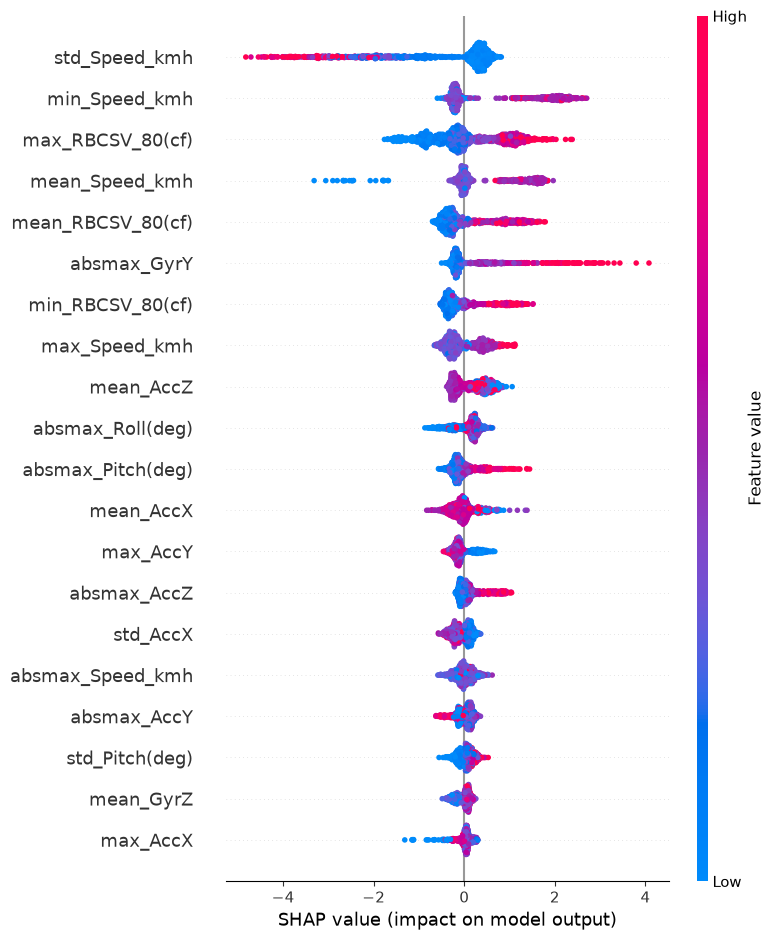

In [62]:
import shap
from sklearn.ensemble import RandomForestClassifier

# readable names for the 45 columns, in the same order clip_features builds them
names = [f"{s}_{f}" for s in ["mean", "std", "min", "max", "absmax"] for f in feature_cols]

Ftr = clip_features(Xtr)
Fte = clip_features(Xte)

model = HistGradientBoostingClassifier(class_weight="balanced", random_state=42).fit(Ftr, ytr)

explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(Fte)

# depending on the shap version, a binary model returns a list or a 3D array
if isinstance(sv, list):
    sv = sv[1]
elif sv.ndim == 3:
    sv = sv[:, :, 1]

shap.summary_plot(sv, Fte, feature_names=names)